## Evaluating a collected day against a GOLD day

This notebook compares two JSON descriptions of a day in somebody's life:

* the **key**: the GOLD description, e.g. one of the example days in ```data/example_days```
* the **collected** description: the day collected by an agent, e.g. by the ```DayInterviewer``` in ```src/cltl/demo_chatbot```, saved in ```data/collected_days```

Both files have the same structure: ```event1```, ```event2```, ... with the roles ```who```, ```what```, ```with_what```, ```with_whom```, ```where```, ```when``` and ```how_long``` and the ```coreference_chains``` of the people in the events.

First we show the basic statistics of both days with ```day_statistics.py```, then we evaluate the collected day against the key with ```day_evaluation.py```.

In [1]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import json
import pandas as pd
from IPython.display import display
from src.cltl.demo_chatbot.day_statistics import save_day_statistics, get_events
from src.cltl.task_evaluation.day_evaluation import evaluate_files, save_turn_evaluation, read_turn_effectiveness,EVENT_THRESHOLD

## The two days

Set ```KEY``` to the GOLD day and ```COLLECTED``` to the day collected by the agent. By default, the collected day is the most recent day in ```data/collected_days```. The evaluation is most meaningful when the collected day describes the same day as the key, e.g. when you told the agent about the day of Emma in ```day1_emma_student.json```.

```EVENT_THRESHOLD``` is the minimal similarity to align a collected event with a GOLD event, from the time, the event type and the label of the events (see ```day_evaluation.py```).

```MAX_GOLD_EVENTS``` limits the evaluation to the first events of the GOLD day, e.g. when the conversation stopped before the end of the day: ```None``` evaluates all GOLD events, a number such as ```4``` the first 4 GOLD events and ```"collected"``` as many GOLD events as the collected day has. The GOLD events that are left out do not count as missed (false negatives). Note that the cut is made on the order of the GOLD events, not on the time: if the agent skipped part of the day, a collected event can match a GOLD event that falls outside the limit.

In [24]:
KEY = PROJECT_ROOT / "data" / "example_days" / "day1_emma_student.json"

# the most recent collected day, skipping the files with statistics and evaluations
collected_days = [path for path in (PROJECT_ROOT / "data" / "collected_days").glob("*.json")
                  if not path.stem.endswith(("_meta", "_evaluation", "_effectiveness"))]
#COLLECTED = max(collected_days, key=lambda path: path.stat().st_mtime) if collected_days else None
COLLECTED = PROJECT_ROOT / "data" / "collected_days" / "day_emma_hour_by_hour_20261022_1104.json"
COLLECTED = PROJECT_ROOT / "data" / "collected_days" / "day_emma_part_of_day_20261022_1149.json"

MAX_GOLD_EVENTS = None ## all gold events are considered
#MAX_GOLD_EVENTS = "collected" ## upto the number of collected events
print("Key:      ", KEY)
print("Collected:", COLLECTED)

Key:       /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/example_days/day1_emma_student.json
Collected: /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_part_of_day_20261022_1149.json


## Statistics of the two days

```save_day_statistics``` computes the statistics of a day and saves them next to the day as ```<name>_meta.json```. We show the statistics of both days next to each other.

In [25]:
key_meta, key_statistics = save_day_statistics(str(KEY))
collected_meta, collected_statistics = save_day_statistics(str(COLLECTED))
print("Saved", key_meta)
print("Saved", collected_meta)

counts = ["nr_of_events", "nr_of_roles", "nr_of_roles_from_photos", "nr_of_coreference_chains",
          "average_nr_of_mentions_per_chain", "nr_of_unique_what", "nr_of_unique_with_what"]
pd.DataFrame({"key": {count: key_statistics.get(count) for count in counts},
              "collected": {count: collected_statistics.get(count) for count in counts}})

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/example_days/day1_emma_student_meta.json
Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_part_of_day_20261022_1149_meta.json


,key,collected
nr_of_events,20.00,13.00
nr_of_roles,127.00,55.00
nr_of_roles_from_photos,5.00,0.00
nr_of_coreference_chains,14.00,3.00
average_nr_of_mentions_per_chain,2.79,6.33
nr_of_unique_what,22.00,9.00
nr_of_unique_with_what,34.00,11.00


The number of events in which each role is filled:

In [26]:
pd.DataFrame({"key": key_statistics["nr_of_roles_per_role"],
              "collected": collected_statistics["nr_of_roles_per_role"]})

,key,collected
who,20,13
what,15,5
with_what,20,6
with_whom,12,4
where,20,13
when,20,13
how_long,20,1


The values of ```what``` and ```with_what``` with the number of events in which they are mentioned, for the key and the collected day:

In [27]:
def frequency_table(role):
    return pd.DataFrame({"key": pd.Series(key_statistics[role], dtype="Int64"),
                         "collected": pd.Series(collected_statistics[role], dtype="Int64")}).fillna(0)

for role in ["what", "with_what"]:
    print(role)
    display(frequency_table(role).sort_values(["key", "collected"], ascending=False))

what


,key,collected
pasta,3,0
vegetables,2,0
coffee,1,2
yoghurt,1,1
apple,1,0
bottle of prosecco,1,0
cappuccino,1,0
cheese,1,0
cheese sandwich,1,0
clothes,1,0


with_what


,key,collected
laptop,4,0
bicycle,2,1
debit card,2,0
phone alarm,2,0
water bottle,2,0
pan,1,1
WhatsApp,1,0
bowl,1,0
cutlery,1,0
cutting board,1,0


The number of mentions in each coreference chain:

In [28]:
display(pd.Series(key_statistics["nr_of_mentions_per_chain"], name="key mentions").to_frame())
display(pd.Series(collected_statistics["nr_of_mentions_per_chain"], name="collected mentions").to_frame())

,key mentions
emma,20
lotte,3
ahmed,2
jonas,2
mila,3
sven,1
fellow_students,1
lecturer,1
dr_bakker,1
mother,1


,collected mentions
emma,13
lotte,4
suzie,2


## Evaluation

```evaluate_files``` evaluates the collected day against the key in two modes and saves the results next to the collected day as ```<collected>_vs_<key>_evaluation.json```:

* **exact**: the labels are the same, ignoring case and spaces
* **jaccard**: the overlap of the words of the labels, so that partial matches get partial credit, e.g. ```alarm``` and ```phone alarm``` score 0.5

In both modes, ```where``` and ```when``` are weighted by the specificity of the match: matching the most specific value scores 1, matching only e.g. ```Europe``` or ```morning``` much less. ```who``` and ```with_whom``` are matched through the coreference chains, so that e.g. ```his wife Gerda``` and ```Gerda``` match.

The evaluation is done on three levels:

* **events**: are the events of the key found in the collected day?
* **roles**: are the roles of the aligned events filled in both days?
* **role-fillers**: do the values of the roles match?

For each level, we get a contingency table with the true positives (TP), false positives (FP), false negatives (FN) and true negatives (TN), and the precision, recall and f1. True negatives are only defined for roles (a role that is empty in both days), for events and role-fillers they are n/a.

In [29]:
evaluation = evaluate_files(str(KEY), str(COLLECTED), event_threshold=EVENT_THRESHOLD, verbose=False,
                            max_gold_events=MAX_GOLD_EVENTS)
print("Saved", evaluation["output"])
print(f"Evaluated {evaluation['nr_of_gold_events']} GOLD events")

COLUMNS = ["tp", "fp", "fn", "tn", "precision", "recall", "f1"]

def level_table(results, level):
    """The contingency table of a level, with a row for the total and for each role."""
    return pd.DataFrame(results[level]).T[COLUMNS].rename(index={"total": f"{level} total"})

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_part_of_day_20261022_1149_vs_day1_emma_student_evaluation.json
Evaluated 20 GOLD events


### Summary

The totals for the three levels in both modes:

In [30]:
rows = {}
for mode, results in evaluation["modes"].items():
    rows[(mode, "events")] = results["events"]
    rows[(mode, "roles")] = results["roles"]["total"]
    rows[(mode, "role-fillers")] = results["role_fillers"]["total"]
pd.DataFrame(rows).T[COLUMNS]

tp      fp       fn   tn  precision  recall     f1
exact   events         2.000  11.000   18.000  NaN      0.154   0.100  0.121
        roles          9.000  46.000  118.000  2.0      0.164   0.071  0.099
        role-fillers   8.286  58.714  156.714  NaN      0.124   0.050  0.071
jaccard events         5.000   8.000   15.000  NaN      0.385   0.250  0.303
        roles         20.000  35.000  107.000  4.0      0.364   0.157  0.220
        role-fillers  13.671  53.329  151.329  NaN      0.204   0.083  0.118

### Roles and role-fillers per role

For each mode, the contingency tables of the roles and of the role-fillers, with the total and each role:

In [31]:
for mode, results in evaluation["modes"].items():
    print(f"Mode: {mode}")
    display(level_table(results, "roles"))
    display(level_table(results, "role_fillers"))

Mode: exact


,tp,fp,fn,tn,precision,recall,f1
roles total,9.0,46.0,118.0,2.0,0.164,0.071,0.099
who,2.0,11.0,18.0,0.0,0.154,0.100,0.121
what,1.0,4.0,14.0,1.0,0.200,0.067,0.100
with_what,1.0,5.0,19.0,0.0,0.167,0.050,0.077
with_whom,1.0,3.0,11.0,1.0,0.250,0.083,0.125
where,2.0,11.0,18.0,0.0,0.154,0.100,0.121
when,2.0,11.0,18.0,0.0,0.154,0.100,0.121
how_long,0.0,1.0,20.0,0.0,0.000,0.000,0.000


,tp,fp,fn,tn,precision,recall,f1
role_fillers total,8.286,58.714,156.714,NaN,0.124,0.050,0.071
who,2.000,11.000,18.000,NaN,0.154,0.100,0.121
what,2.000,8.000,23.000,NaN,0.200,0.080,0.114
with_what,0.000,11.000,41.000,NaN,0.000,0.000,0.000
with_whom,1.000,5.000,18.000,NaN,0.167,0.053,0.080
where,1.286,11.714,18.714,NaN,0.099,0.064,0.078
when,2.000,11.000,18.000,NaN,0.154,0.100,0.121
how_long,0.000,1.000,20.000,NaN,0.000,0.000,0.000


Mode: jaccard


,tp,fp,fn,tn,precision,recall,f1
roles total,20.0,35.0,107.0,4.0,0.364,0.157,0.220
who,5.0,8.0,15.0,0.0,0.385,0.250,0.303
what,2.0,3.0,13.0,1.0,0.400,0.133,0.200
with_what,2.0,4.0,18.0,0.0,0.333,0.100,0.154
with_whom,1.0,3.0,11.0,3.0,0.250,0.083,0.125
where,5.0,8.0,15.0,0.0,0.385,0.250,0.303
when,5.0,8.0,15.0,0.0,0.385,0.250,0.303
how_long,0.0,1.0,20.0,0.0,0.000,0.000,0.000


,tp,fp,fn,tn,precision,recall,f1
role_fillers total,13.671,53.329,151.329,NaN,0.204,0.083,0.118
who,5.000,8.000,15.000,NaN,0.385,0.250,0.303
what,2.500,7.500,22.500,NaN,0.250,0.100,0.143
with_what,0.000,11.000,41.000,NaN,0.000,0.000,0.000
with_whom,1.000,5.000,18.000,NaN,0.167,0.053,0.080
where,2.571,10.429,17.429,NaN,0.198,0.129,0.156
when,2.600,10.400,17.400,NaN,0.200,0.130,0.158
how_long,0.000,1.000,20.000,NaN,0.000,0.000,0.000


### Aligned events

The next cell shows which events of the key (```gold```) are aligned with which events of the collected day (```system```), with their ```similarity```. The alignment can differ per mode, since the labels are compared in the mode of the evaluation. We show the alignment of the jaccard mode.

**How the similarity is determined.** Each GOLD event is compared with each collected event:

```
similarity = 0.5 * time + 0.25 * type + 0.25 * label
```

* **time** (half of the score): the overlap of the two time intervals (from ```when``` and ```how_long```), or the closeness of the start times if that is higher: 1 for the same start time, 0.5 for 30 minutes apart, 0 for an hour or more apart. An event without a clock time, e.g. only ```morning``` in ```when```, gets 0.5 if the other event is in the same part of the day.
* **type**: 1 if the ```event_type``` is the same, 0 otherwise.
* **label**: the match of the ```event_label``` in the mode of the evaluation, e.g. the jaccard overlap of the words. The ```description``` is not used.

The events are then aligned one-to-one with the highest total similarity, and only pairs with a similarity of at least ```EVENT_THRESHOLD``` (0.55) are kept. Time alone is not enough: the type or the label has to match as well. An aligned event counts as one correct event, also with a similarity below 1.

For example, if the collected event *waking up* starts at 07:00 and the GOLD event *waking up* at 07:30, the time similarity is 0.5 and the type and label match: 0.5 * 0.5 + 0.25 + 0.25 = 0.75.

**The comment.** Each aligned pair has a ```comment``` in the evaluation JSON that explains the mismatch: the parts of the similarity, the time, type or label that differ, and each role of which the values do not fully match the GOLD, with its score. These role scores are the role-fillers in the tables above:

* lists of values such as ```what``` and ```with_whom``` count the matched values, e.g. ```alarm clock``` and ```phone alarm``` match for 1/3 in jaccard mode (one shared word of three)
* ```where``` and ```when``` score the best matching GOLD value by its specificity: GOLD value i of n scores (n - i + 1) / n. If the collected event has 07:00 instead of 07:30, only ```7 o'clock```, value 3 of 5, matches, which scores 3/5 = 0.6
* ```how_long``` scores the shortest duration divided by the longest, e.g. 5 instead of 10 minutes scores 0.5


In [32]:
MODE = "jaccard"
alignment = pd.DataFrame(evaluation["modes"][MODE]["event_alignment"])
display(alignment.drop(columns="comment", errors="ignore"))

# the comment explains the similarity and the roles that do not fully match the GOLD
for pair in evaluation["modes"][MODE]["event_alignment"]:
    print(f"\n{pair['gold']} '{pair['gold_label']}' - {pair['system']} '{pair['system_label']}': {pair['similarity']}")
    for part in pair["comment"].split("; "):
        print("   ", part)

,gold,system,similarity,gold_label,system_label
0,event1,event1,0.833,waking up,wake up
1,event3,event4,1.000,breakfast,breakfast
2,event8,event8,0.625,lunch,having lunch
3,event13,event9,0.562,grocery shopping,doing some shopping
4,event18,event12,0.667,watching a series,watching a Netflix series



event1 'waking up' - event1 'wake up': 0.833
    similarity = 0.5 * time 1.00 + 0.25 * type 1.00 + 0.25 * label 0.33
    label: 'wake up' instead of 'waking up'
    with_what: missing, GOLD ['phone alarm']
    where 0.43: the best match is 'bedroom of her house' with 'bedroom', GOLD value 2 of 7, which scores 6/7, the most specific GOLD value is 'bedroom in her student flat'
    how_long: missing, GOLD [10]

event3 'breakfast' - event4 'breakfast': 1.0
    similarity = 0.5 * time 1.00 + 0.25 * type 1.00 + 0.25 * label 1.00
    what 2.00 of 3 GOLD values matched: collected ['yoghurt', 'fruit', 'coffee'], GOLD ['yoghurt', 'granola', 'coffee']
    with_what 0.00 of 3 GOLD values matched: collected ['kitchen of her house', 'kitchen', 'her house', 'Amsterdam', 'Europe'], GOLD ['bowl', 'spoon', 'mug']
    with_whom 1.00 of 1 GOLD values matched: collected ['Lotte', 'Suzie'], GOLD ['flatmate Lotte']
    where 0.86: the best match is 'kitchen', GOLD value 2 of 7, which scores 6/7, the most sp

The events of the key that are missed (false negatives) and the events of the collected day that are not in the key (false positives):

In [33]:
with open(KEY) as json_file:
    key_events = get_events(json.load(json_file))
with open(COLLECTED) as json_file:
    collected_events = get_events(json.load(json_file))

aligned_key = set(alignment["gold"]) if len(alignment) else set()
aligned_collected = set(alignment["system"]) if len(alignment) else set()

def event_rows(events, aligned):
    return pd.DataFrame([{"event": key, "event_label": event["event_label"], "when": event["when"][0],
                          "how_long": event["how_long"]}
                         for key, event in events.items() if key not in aligned])

print("Missed events of the key")
display(event_rows(key_events, aligned_key))
print("Events of the collected day that are not in the key")
display(event_rows(collected_events, aligned_collected))

Missed events of the key


,event,event_label,when,how_long
0,event2,showering,07:40,20
1,event4,cycling to university,08:25,20
2,event5,attending lecture,09:00,105
3,event6,coffee break,10:50,15
4,event7,group project meeting,11:10,80
5,event9,signing an internship contract,13:05,40
6,event10,calling parents,13:50,15
7,event11,self-study,14:15,90
8,event12,cycling to the supermarket,15:50,15
9,event14,going to the gym,17:00,45


Events of the collected day that are not in the key


,event,event_label,when,how_long
0,event2,shower,morning,NaN
1,event3,get dressed,morning,NaN
2,event5,bike to university,09:00,NaN
3,event6,study at the library,10:00,NaN
4,event7,going to class,afternoon,NaN
5,event10,cleaning her room,afternoon,NaN
6,event11,dinner with friends,evening,NaN
7,event13,reading before bed,22:00,30.0


### Aligned entities

The entities of the coreference chains of the key that are aligned with the entities of the collected day. Mentions of aligned entities match for ```who``` and ```with_whom```.

In [34]:
pd.Series(evaluation["modes"][MODE]["entity_alignment"], name="collected entity").rename_axis("key entity").to_frame()

,collected entity
key entity,
emma,emma
lotte,lotte


## Effectiveness of the communication

```save_turn_evaluation``` evaluates each turn of the conversation and saves it as ```<collected>_vs_<key>_turn_evaluation.csv```, in the format of the EMISSOR evaluation files: a row for each question of the agent and each answer of the user, with the number of events and roles extracted from the answer and the number of correct events and roles in both modes. This file can be plotted with the ```plots``` module.

The effectiveness of the communication tells how much the agent gets out of the conversation. For the events, the roles and the correct events and roles (in both modes), we give:

* **total**: the total number in the conversation
* **average per user turn**: the average number per answer of the user, i.e. the total divided by the number of user turns
* **ratio per turn**: the total divided by the number of all turns, the questions of the agent included, i.e. what each turn of the conversation yields

An agent that gets more correct roles with fewer turns communicates more effectively. The numbers are saved next to the collected day as ```<collected>_vs_<key>_turn_effectiveness.json```. The turns are the turns of the collected events, so the questions about the name and the hour at which the day started are not counted, and neither are the answers to skipped questions.

In [35]:
turn_csv = save_turn_evaluation(str(KEY), str(COLLECTED), event_threshold=EVENT_THRESHOLD, verbose=False,
                                max_gold_events=MAX_GOLD_EVENTS)
print("Saved", turn_csv)
effectiveness = read_turn_effectiveness(turn_csv)
print(f"{effectiveness['nr_of_turns']} turns: {effectiveness['nr_of_agent_turns']} of the agent, "
      f"{effectiveness['nr_of_user_turns']} of the user")
pd.DataFrame(effectiveness["counts"]).T.rename(columns={"average_per_user_turn": "average per user turn",
                                                         "ratio_per_turn": "ratio per turn"})

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_part_of_day_20261022_1149_vs_day1_emma_student_turn_evaluation.csv
6 turns: 3 of the agent, 3 of the user


,total,average per user turn,ratio per turn
nr_of_events,13.000,4.333,2.167
nr_of_roles,55.000,18.333,9.167
nr_of_correct_events_exact,2.000,0.667,0.333
nr_of_correct_events_jaccard,5.000,1.667,0.833
nr_of_correct_roles_exact,6.453,2.151,1.076
nr_of_correct_roles_jaccard,11.590,3.863,1.932


## Running the evaluation from the command line

The statistics and the evaluation can also be run from a terminal in the root of the project:

```
python -m src.cltl.demo_chatbot.day_statistics data/example_days data/collected_days
python -m src.cltl.task_evaluation.day_evaluation --key data/example_days/day1_emma_student.json --collected data/collected_days/<your day>.json
```

## Plotting the conversation

The CSV file can be plotted with the ```plots``` module, like the CSV files of the EMISSOR analyses. Each turn is shown on the X-axis. The first plot shows two lines: the number of events and the number of roles extracted from each answer of the user. The second plot shows the number of correct events and correct roles (jaccard mode). The questions of the agent are shown on the X-axis, but have no points, since the agent does not extract anything itself. ```create_timeline_image_from_csv_columns``` can plot any columns of the CSV file together in this way. The plots are saved next to the CSV file. A conversation of 20 events has more than a hundred turns, so the plots are wide: scroll horizontally to see all turns, or set ```settings._START``` and ```settings._END``` to plot a part of the conversation, e.g. the turns 0 to 40.

In [36]:
from src.cltl.emissor_evaluation.plots import plot_interaction as plot

Nr of turns 6
Nr of turns 6
Saved plot to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_part_of_day_20261022_1149_vs_day1_emma_student_turn_evaluation_extracted_plot.png



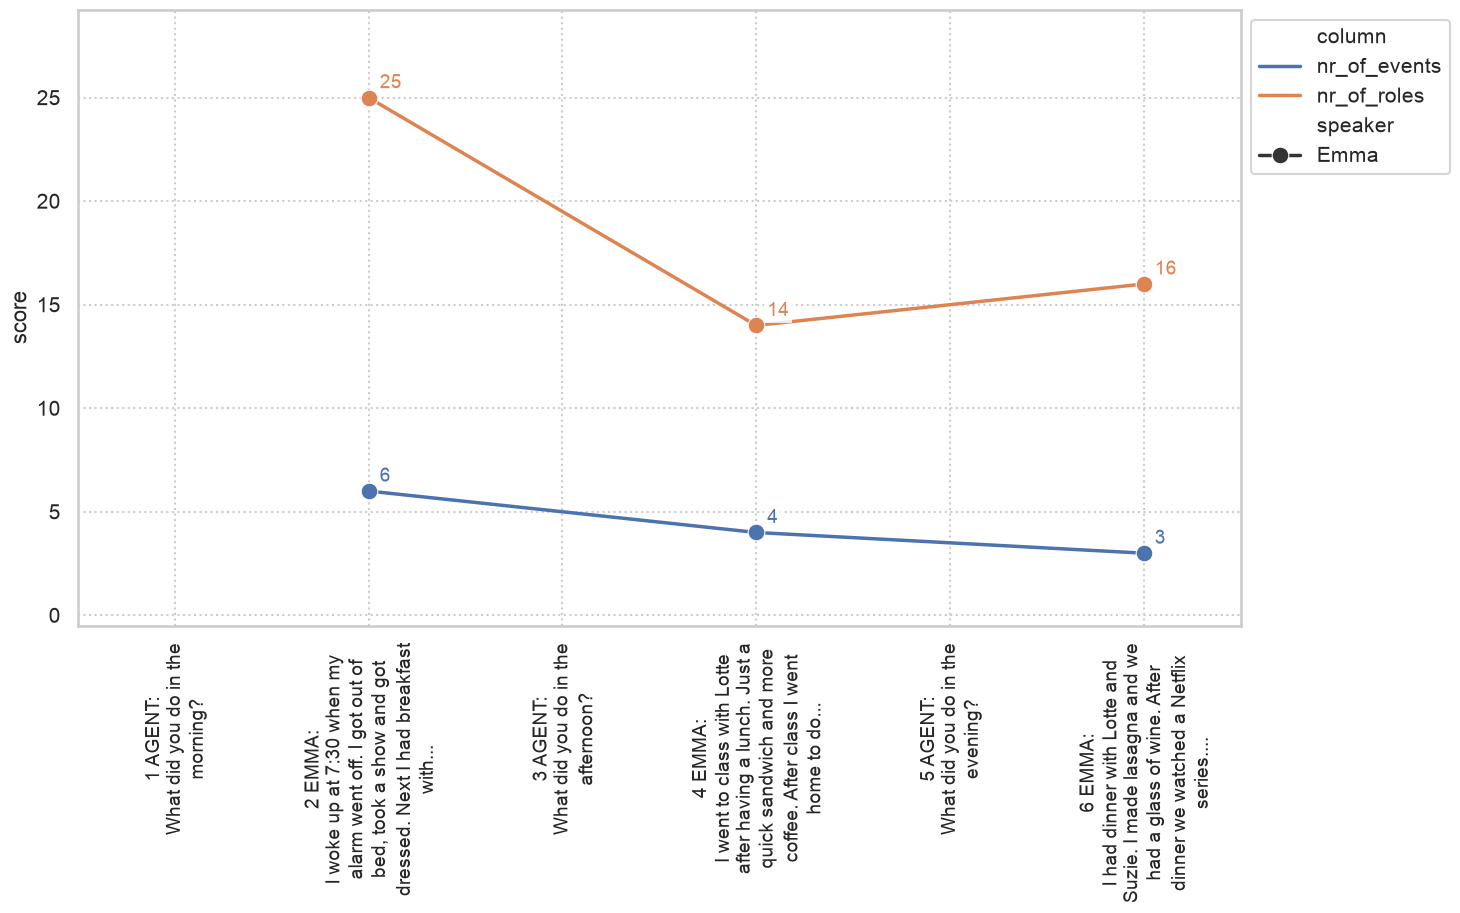

In [37]:
settings = plot.PlotSettings()
plot_file = plot.create_timeline_image_from_csv_columns(turn_csv, ["nr_of_events", "nr_of_roles"], settings,
                                                        name="extracted")

Nr of turns 6
Nr of turns 6
Saved plot to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_part_of_day_20261022_1149_vs_day1_emma_student_turn_evaluation_correct_jaccard_plot.png



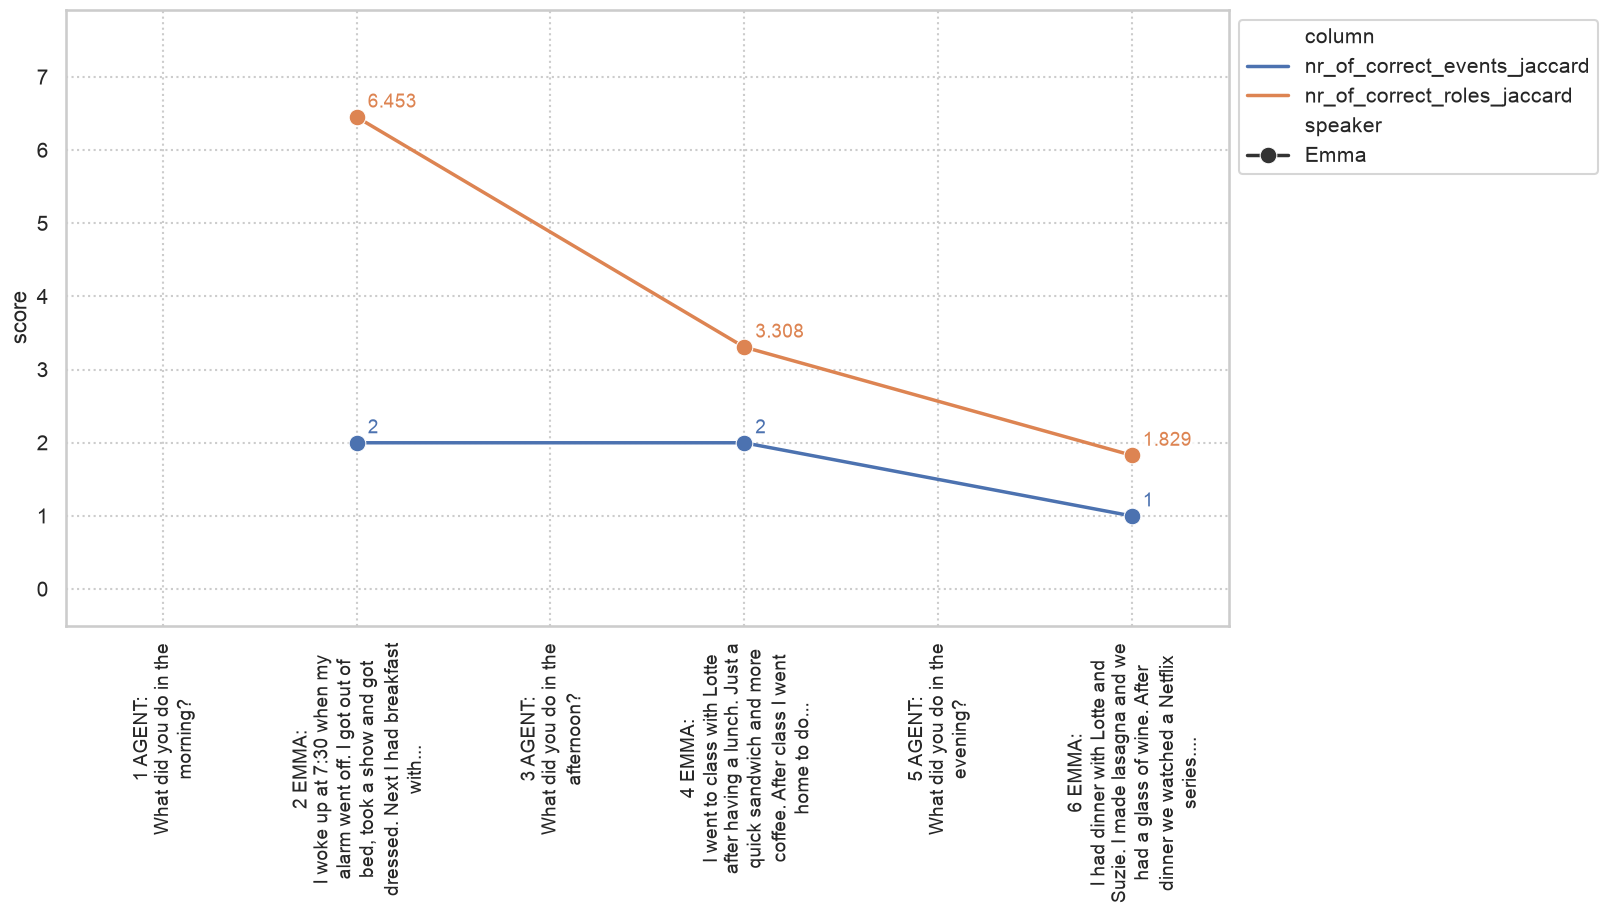

In [38]:
plot_file = plot.create_timeline_image_from_csv_columns(
    turn_csv, ["nr_of_correct_events_jaccard", "nr_of_correct_roles_jaccard"], settings, name="correct_jaccard")